In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
base = "https://www.nomisweb.co.uk/api/v01/dataset/{}.data.csv"

settings = (
    "?geography=2092957697,2092957698,TYPE480"   # UK, GB, regions
    "&date=latestMINUS23-latest"                  # last 23 years
    "&sex=8"                                      # full-time
    "&item=2"                                     # median
    "&pay=1"                                      # gross weekly pay
    "&measures=20100"
    "&select=date_name,geography_name,obs_value"
)

residence = pd.read_csv(base.format("NM_30_1") + settings)
workplace = pd.read_csv(base.format("NM_99_1") + settings)

print("Residence:", residence.shape)
print("Workplace:", workplace.shape)

Residence: (336, 3)
Workplace: (336, 3)


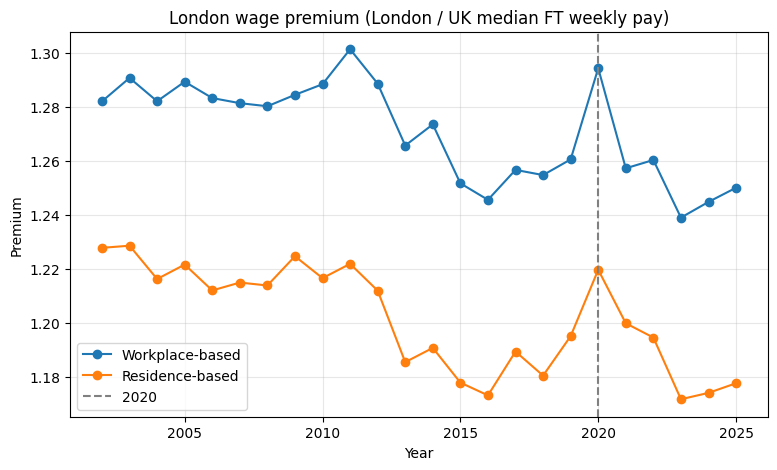

,Workplace,Residence
DATE_NAME,,
2002,1.282,1.228
2003,1.291,1.228
2004,1.282,1.216
2005,1.289,1.221
2006,1.283,1.212
2007,1.281,1.215
2008,1.280,1.214
2009,1.284,1.225
2010,1.288,1.216


In [3]:
# save raw data for the repo
residence.to_csv("ashe_residence.csv", index=False)
workplace.to_csv("ashe_workplace.csv", index=False)

# London median / UK median, by year
def london_premium(df):
    wide = df.pivot(index="DATE_NAME", columns="GEOGRAPHY_NAME", values="OBS_VALUE")
    return wide["London"] / wide["United Kingdom"]

prem_work = london_premium(workplace)
prem_res = london_premium(residence)

# plot both measures
plt.figure(figsize=(9, 5))
plt.plot(prem_work.index, prem_work, marker="o", label="Workplace-based")
plt.plot(prem_res.index, prem_res, marker="o", label="Residence-based")
plt.axvline(2020, color="grey", linestyle="--", label="2020")
plt.title("London wage premium (London / UK median FT weekly pay)")
plt.ylabel("Premium")
plt.xlabel("Year")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("chart1_londn_premium.png", dpi=200, bbox_inches="tight")
plt.show()

# table of values
pd.DataFrame({"Workplace": prem_work.round(3), "Residence": prem_res.round(3)})

In [4]:
df = pd.DataFrame({"Workplace": prem_work, "Residence": prem_res})
df["Gap"] = df["Workplace"] - df["Residence"]

summary = pd.DataFrame({
    "2002-07": df.loc[2002:2007].mean(),
    "2017-19": df.loc[2017:2019].mean(),
    "2022-25": df.loc[2022:2025].mean(),
})
summary["Change 02-07 to 17-19"] = summary["2017-19"] - summary["2002-07"]
summary["Change 17-19 to 22-25"] = summary["2022-25"] - summary["2017-19"]
summary.round(3)

,2002-07,2017-19,2022-25,Change 02-07 to 17-19,Change 17-19 to 22-25
Workplace,1.285,1.257,1.248,-0.027,-0.009
Residence,1.220,1.188,1.179,-0.032,-0.009
Gap,0.065,0.069,0.069,0.004,0.000


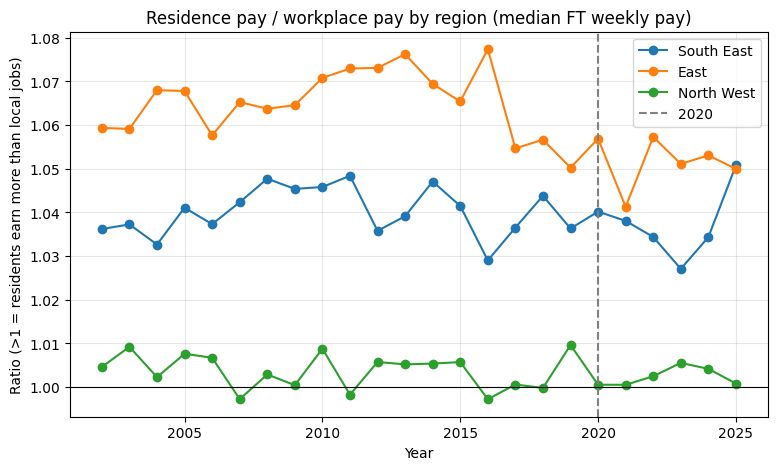

,2017-19,2022-25,Change
GEOGRAPHY_NAME,,,
South East,1.039,1.037,-0.002
East,1.054,1.053,-0.001
North West,1.003,1.003,-0.000


In [5]:
# residence pay / workplace pay, by region
res_w = residence.pivot(index="DATE_NAME", columns="GEOGRAPHY_NAME", values="OBS_VALUE")
work_w = workplace.pivot(index="DATE_NAME", columns="GEOGRAPHY_NAME", values="OBS_VALUE")
ratio = res_w / work_w

regions = ["South East", "East", "North West"]

plt.figure(figsize=(9, 5))
for r in regions:
    plt.plot(ratio.index, ratio[r], marker="o", label=r)
plt.axvline(2020, color="grey", linestyle="--", label="2020")
plt.axhline(1, color="black", linewidth=0.8)
plt.title("Residence pay / workplace pay by region (median FT weekly pay)")
plt.ylabel("Ratio (>1 = residents earn more than local jobs)")
plt.xlabel("Year")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("chart2_commuter_belt.png", dpi=200, bbox_inches="tight")
plt.show()

# before vs after
t2 = pd.DataFrame({
    "2017-19": ratio.loc[2017:2019, regions].mean(),
    "2022-25": ratio.loc[2022:2025, regions].mean(),
})
t2["Change"] = t2["2022-25"] - t2["2017-19"]
t2.round(3)